## Injection tests of the location decoders
Planted-change checks of the sliding LDA and of the masked LaBraM decoder, moved from `LDA.ipynb`. The setup cells
below are copies of the `LDA.ipynb` helpers these tests use (filters, loaders, topomaps, Task B contrasts) and the
accuracy window of the real data, chosen the same way.

In [2]:
import os

import numpy as np
import pandas as pd

from core import settings, plot_data_processing
from core import io
from core.decoding.data import band_file_name

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir('..')

run_lda = False

In [3]:
from core import utils

# filters of the analysis, as in plasticity_plotting.ipynb. They select the trials loaded from the saved outputs only
subjects = None  # set to None to load all subjects
conditions = None  # set to None to load all location conditions; with a subset, the per-class AUCs of the missing classes can't be computed
id_low, id_high = None, None
trial_ids = [i for i in range(id_low, id_high)] if id_low is not None and id_high is not None else None  # set to None to load all trial ids
exclude_left_patched = True
exclude_right_patched_lefties = True  # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False  # set to True to exclude button press trials (everything before STMD59)

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT / "rightpatch_eye_dominance.csv"))  # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)

In [4]:
# load the saved data
CH_NAMES = [name.replace("EEG ", "").replace("-REF", "") for name in settings.CHORDER_STANDARD]  # e.g. FP1, in the channel order of the outputs


def load_filtered_merged(model_name, mode="trial", ch_names=CH_NAMES, sessions=("baseline", "postpatch")):
    """
    The trial table (class_trials_frame) or, with mode="channel", the channel table (class_channels_frame) of the given
    sessions of a class run, all folds, with the filters above. A run trained on post-patching data has post-patching
    outputs only, sessions=("postpatch",).
    """
    run_dir = settings.INFERENCE_DIR / model_name
    folds = sorted(int(d.name) for d in run_dir.iterdir() if d.is_dir() and d.name.isdigit())
    frames = []
    for session in sessions:
        merged = []
        for i in folds:
            file_path = settings.INFERENCE_DIR / model_name / str(i) / f"{session}_reconstruction.h5"
            merged.extend(io.load_inference_trials(file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects, window="full", stim_patch=None))
        if mode == "channel":
            frames.append(plot_data_processing.class_channels_frame(merged, model_name, session=session, ch_names=ch_names))
        else:
            frames.append(plot_data_processing.class_trials_frame(merged, model_name, session=session))
    return pd.concat(frames, ignore_index=True)

In [5]:
import matplotlib.pyplot as plt
import mne

topo_info = plot_data_processing.create_topomap_info()  # 10-20 labels at the HydroCel positions, in CH_NAMES order

def channel_change_topomaps(df, label, value="occlusion_effect", relative=False, model_label="masked LaBraM decoder"):
    """
    Topomaps of a per-channel column of a channel table (class_channels_frame): the subject means per session (baseline
    and post-patching on one colour scale), the mean change (post-patching - baseline) and its d_z over the subjects with
    both sessions. NaN (interpolated) rows are left out of the subject means. Prints the 3 channels with the largest and
    the 3 with the smallest change.
    relative (occlusion only): the subject's mean drop divided by its mean true-class probability without hiding, per
    session and channel (a ratio of means: per-trial ratios explode for trials with a true-class probability near 0).
    """
    grouped = df.groupby(["session", "subject", "channel"])
    subject_means = grouped[value].mean()
    if relative:
        subject_means = subject_means / grouped["p_true"].mean()  # p_true is NaN on the same (interpolated) rows
    subject_means = subject_means.unstack("channel")[CH_NAMES]
    baseline, postpatch = subject_means.loc["baseline"], subject_means.loc["postpatch"]
    subjects = baseline.index.intersection(postpatch.index)
    change = postpatch.loc[subjects] - baseline.loc[subjects]
    maps = {"baseline": baseline.loc[subjects].mean(), "post-patching": postpatch.loc[subjects].mean(),
            "change (post - baseline)": change.mean(), "d_z of the change": change.mean() / change.std(ddof=1)}
    # the session maps share one scale: symmetric around 0 if the values can be negative, from min to max otherwise
    session_values = pd.concat([maps["baseline"], maps["post-patching"]])
    if session_values.min() < 0:
        session_vlim, session_cmap = (-session_values.abs().max(), session_values.abs().max()), "RdBu_r"
    else:
        session_vlim, session_cmap = (session_values.min(), session_values.max()), "viridis"

    fig, axes = plt.subplots(1, len(maps), figsize=(5 * len(maps), 4.5))
    for ax, (title, values) in zip(axes, maps.items()):
        session_map = title in ("baseline", "post-patching")
        vlim = session_vlim if session_map else (-values.abs().max(), values.abs().max())
        values = values.to_numpy(dtype=float)
        keep = np.flatnonzero(np.isfinite(values))
        im, _ = mne.viz.plot_topomap(values[keep], mne.pick_info(topo_info, keep), axes=ax, show=False, vlim=vlim,
                                     cmap=session_cmap if session_map else "RdBu_r")
        ax.set_title(title)
        fig.colorbar(im, ax=ax, shrink=0.7)
    fig.suptitle(f"{label}, {model_label} (N={len(subjects)} subjects)", y=1.03)
    plt.show()

    ordered = maps["change (post - baseline)"].dropna().sort_values()
    print(f"{label}, change (post - baseline):")
    print("  max: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[::-1][:3].items()))
    print("  min: " + ", ".join(f"{ch} {v:+.4f}" for ch, v in ordered[:3].items()))

In [6]:
import h5py
import matplotlib.pyplot as plt
from core.decoding import metrics as decoding_metrics

sliding_name = "sliding_lda"  # output folder of decoding/run_sliding_lda.py
n_permutations = 5000


def load_time_metrics(name, file_suffix="reconstruction"):
    """
    Per-subject time metrics (decoding_metrics.time_metrics_frame) of both sessions of a sliding decoder, with the filters
    above, from its {session}_{file_suffix}.h5 files ("searchlight": the searchlight outputs, one set per channel).
    """
    run_dir = settings.INFERENCE_DIR / name
    folds = sorted(int(d.name) for d in run_dir.iterdir() if d.is_dir() and d.name.isdigit())
    frames = []
    for session in ("baseline", "postpatch"):
        trials = []
        for k in folds:
            path = run_dir / str(k) / f"{session}_{file_suffix}.h5"
            with h5py.File(path, "r") as f:
                set_names, times = [str(s) for s in f.attrs["sets"]], np.asarray(f.attrs["times"])
            trials.extend(io.load_inference_trials(path, subjects=subjects, conditions=conditions, idxs=trial_ids,
                                                   exclude_subjects=exclude_subjects, stim_patch=None))
        frames.append(decoding_metrics.time_metrics_frame(trials, name, session, set_names, times, settings.N_LOCATION_CLASSES))
    return pd.concat(frames, ignore_index=True), set_names, times

In [7]:
def q4_contrasts(time_df, accuracy_window, set_name):
    """
    The Task B contrast table of a time table (load_time_metrics): per-subject one-vs-rest AUC curves of set_name, the
    classes as side slots relative to the patched eye (subjects with both sessions and a known patched eye), accuracy =
    mean AUC in accuracy_window, latency = fractional peak latency of the smoothed mean curves (jackknife), Holm-corrected
    per kind. Returns (contrast table, Q4 subjects).
    """
    auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == set_name)]

    def class_curves(session):  # {subject: (n_classes, n_times)}
        table = auc_df[auc_df["session"] == session].pivot_table(index=["subject", "class"], columns="time", values="value")
        return {s: table.loc[s].reindex(range(settings.N_LOCATION_CLASSES)).to_numpy() for s in table.index.get_level_values(0).unique()}

    baseline_curves, postpatch_curves = class_curves("baseline"), class_curves("postpatch")
    both = sorted(set(baseline_curves) & set(postpatch_curves))
    baseline_slots, q4_subjects = decoding_metrics.side_slots(np.stack([baseline_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
    postpatch_slots, _ = decoding_metrics.side_slots(np.stack([postpatch_curves[s] for s in both]), both, eyes, settings.LOCATION_CLASSES)
    curve_times = np.asarray(auc_df["time"].drop_duplicates().sort_values())

    # accuracy: mean AUC in the window; latency: smoothed curves, fractional peak latency on the mean curves (jackknife)
    in_window = (curve_times >= accuracy_window[0] - 1e-9) & (curve_times <= accuracy_window[1] + 1e-9)
    accuracy = decoding_metrics.accuracy_contrasts(baseline_slots[..., in_window].mean(-1), postpatch_slots[..., in_window].mean(-1))
    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    latency = decoding_metrics.latency_contrasts(curve_times, decoding_metrics.smooth(baseline_slots, smoothing),
                                                 decoding_metrics.smooth(postpatch_slots, smoothing), 0.5,
                                                 settings.Q4_PEAK_FRACTION, settings.Q4_LATENCY_SEARCH)
    q4 = pd.concat([accuracy, latency], ignore_index=True)
    for kind in ("change", "baseline only"):
        q4.loc[q4["kind"] == kind, "p_holm"] = decoding_metrics.holm(q4.loc[q4["kind"] == kind, "p"])
    return q4, q4_subjects


eyes = decoding_metrics.patched_eyes(settings.DATA_ROOT / "eye_dominance.csv", settings.DATA_ROOT / "rightpatch_eye_dominance.csv")

In [8]:
# the real data's sliding LDA outputs, only for the accuracy window, chosen as in LDA.ipynb (Task B, B1)
time_df, set_names, times = load_time_metrics(sliding_name)
primary_set = set_names[0]

auc_df = time_df[(time_df["metric"] == "auc") & (time_df["set"] == primary_set)]

# B1: the accuracy window, from the baseline grand average over all classes only
if settings.Q4_ACCURACY_WINDOW is None:
    grand = auc_df[auc_df["session"] == "baseline"].groupby(["subject", "time"])["value"].mean().unstack("time")
    found = [c for c in decoding_metrics.cluster_test_vs_chance(grand.to_numpy(), 0.5, n_permutations, settings.SEED) if c[2] < 0.05]
    if not found:
        raise ValueError("No baseline cluster above chance, the accuracy window can't be chosen")
    first, last, p = max(found, key=lambda c: c[1] - c[0])
    accuracy_window = (round(float(grand.columns[first]), 3), round(float(grand.columns[last]), 3))
    print(f"Suggested Q4_ACCURACY_WINDOW = {accuracy_window} (baseline cluster p = {p:.4f}); write it into settings before looking at post data")
else:
    accuracy_window = settings.Q4_ACCURACY_WINDOW
print(f"Accuracy window: {accuracy_window} s")

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

## Injection tests
Planted-change checks of the sliding LDA (handoff C2-C4), on the runs of `decoding/run_lda_injection.py`: baseline
trials split into two pseudo-sessions, pseudo pre saved as baseline and pseudo post as post-patching, with a change
planted into the pseudo post trials of one condition per run. Every run is analysed like the real data (Task B, the
accuracy window fixed above). "Side" is the side of the stimulus location: with right-patched subjects, the right
locations are the patched side, so patched - other at mid = change of R_mid - change of L_mid.
- **Null** (C2): no change contrast may be significant after Holm correction.
- **Delay** (C3, `d` s later): the planted class's latency rises by about `d` (`planted class Δ latency`, jackknife), and
  the latency contrast at its eccentricity recovers it: about +d for a patched-side class, -d for the other side.
- **Attenuation** (C4, `a` x the class-average evoked response removed at the posterior channels, 0-0.5 s): the planted
  class's AUC in the window drops (`planted class Δ AUC`), and the accuracy contrast at its eccentricity detects it:
  < 0 for a patched-side class, > 0 for the other side. With searchlight outputs, the planted class's AUC change
  should be negative at the posterior clusters. A decoder retrained on the planted pseudo post can learn the weakened
  class as a new pattern, so this plant may go undetected.
- **Class-specific attenuation** (`classattenuation`, `--class_specific`): as the attenuation, but only the class's
  deviation from the mean over the 8 locations is removed (`a` = 1: no posterior location-specific average left), which a
  retrained decoder can't recover from. Expected as for the attenuation.


In [9]:
from scipy.stats import ttest_1samp

injection_prefix = "lda_injection"  # --name of decoding/run_lda_injection.py
split_seed = 0  # --split_seed of the delay and attenuation runs analysed
null_split_seeds = [0, 1, 2]  # --split_seed of the null runs analysed (C2 repeats the null with 3 splits)


def injection_test(sliding_name, condition=None, show_maps=True):
    """
    Analyses one run of decoding/run_lda_injection.py (output folder sliding_name) like the real data: the Task B
    contrasts (q4_contrasts, broadband, the fixed accuracy window). With the planted condition also that class's change
    (pseudo post - pseudo pre): of its AUC in the window, per subject (t-test), and of its latency, the fractional peak
    latency of the smoothed mean AUC curves (jackknife, as the Task B latencies); with searchlight outputs and show_maps
    the maps of its searchlight AUC - 0.5 in the window.
    Returns (contrast table, Q4 subjects, {"auc": ..., "latency": ...} of the planted class or None).
    """
    injection_df, injection_sets, _ = load_time_metrics(sliding_name)
    contrasts, subjects_q4 = q4_contrasts(injection_df, accuracy_window, injection_sets[0])
    if condition is None:
        return contrasts, subjects_q4, None

    class_id = settings.CONDITION_CLASS_IDS[condition]
    class_rows = injection_df[(injection_df["metric"] == "auc") & (injection_df["set"] == injection_sets[0])
                              & (injection_df["class"] == class_id)]
    window_rows = class_rows[class_rows["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
    window_auc = window_rows.groupby(["session", "subject"])["value"].mean().unstack("session").dropna()
    delta = window_auc["postpatch"] - window_auc["baseline"]
    test = ttest_1samp(delta, 0)
    planted = {"auc": {"estimate": delta.mean(), "se": delta.sem(), "t": test.statistic, "p": test.pvalue, "n": len(delta)}}

    curves = class_rows.pivot_table(index=["subject", "session"], columns="time", values="value")
    both = sorted(set(curves.loc[(slice(None), "baseline"), :].index.get_level_values(0))
                  & set(curves.loc[(slice(None), "postpatch"), :].index.get_level_values(0)))
    curve_times = curves.columns.to_numpy()
    smoothing = round(settings.Q4_LATENCY_SMOOTHING / (curve_times[1] - curve_times[0]))
    data = decoding_metrics.smooth(np.stack([[curves.loc[(s, session)].to_numpy() for session in ("baseline", "postpatch")]
                                             for s in both]), smoothing)  # (n_subjects, 2, n_times)
    latency = lambda mean: decoding_metrics.fractional_peak_latency(curve_times, mean, 0.5, settings.Q4_PEAK_FRACTION, settings.Q4_LATENCY_SEARCH)
    planted["latency"] = decoding_metrics.jackknife(lambda m: latency(m[1]) - latency(m[0]), data)

    searchlight_suffix = f"searchlight_{band_file_name(list(settings.DECODING_BANDS)[0])}"
    if show_maps and (settings.INFERENCE_DIR / sliding_name / "1" / f"baseline_{searchlight_suffix}.h5").exists():
        searchlight_df, _, _ = load_time_metrics(sliding_name, file_suffix=searchlight_suffix)
        rows = searchlight_df[(searchlight_df["metric"] == "auc") & (searchlight_df["class"] == class_id)
                              & searchlight_df["time"].between(accuracy_window[0] - 1e-9, accuracy_window[1] + 1e-9)]
        cluster_df = (rows.groupby(["session", "subject", "set"])["value"].mean() - 0.5).rename("searchlight_auc")
        channel_change_topomaps(cluster_df.reset_index().rename(columns={"set": "channel"}),
                                f"{sliding_name}: {settings.LOCATION_CLASSES[condition]['label']} searchlight AUC - 0.5, "
                                f"{accuracy_window[0]}-{accuracy_window[1]} s", value="searchlight_auc",
                                model_label="sliding LDA on every channel's cluster (pseudo pre vs planted pseudo post)")
    return contrasts, subjects_q4, planted


def recovery_rows(plant_type, condition, size, contrasts, subjects_q4, planted):
    """The rows of one planted run for the recovery table: the planted class's change and the side contrast at its eccentricity."""
    info = settings.LOCATION_CLASSES[condition]
    patched = {eyes[s] for s in subjects_q4}
    # +1 if the planted location is on the patched side of every Q4 subject, -1 if on the other side, NaN if mixed or top
    side_sign = (1 if info["side"] in patched else -1) if len(patched) == 1 and info["side"] != "T" else np.nan
    measure = "latency" if plant_type == "delay" else "accuracy"
    expected = size if plant_type == "delay" else -1
    side_contrast = contrasts[(contrasts["measure"] == measure) & (contrasts["kind"] == "change")
                              & (contrasts["contrast"] == "patched - other") & (contrasts["ecc"] == info["ecc"])]
    planted_measure = planted["latency" if plant_type == "delay" else "auc"]
    return [{"type": plant_type, "class": info["label"], "size": size, "measure": f"planted class Δ {'latency' if plant_type == 'delay' else 'AUC'}",
             "expected": expected if plant_type == "delay" else "< 0", **{k: planted_measure[k] for k in ("estimate", "se", "t", "p", "n")}},
            {"type": plant_type, "class": info["label"], "size": size, "measure": f"patched - other {measure}",
             "expected": side_sign * expected if plant_type == "delay" else {1: "< 0", -1: "> 0"}.get(side_sign, "?"),
             **side_contrast[["estimate", "se", "t", "p", "p_holm", "n"]].iloc[0].to_dict()}]

if run_lda:
    # C2: the null runs, nothing planted. C2 concerns the change contrasts; "baseline only" rows test real differences
    # between the classes, the same in both halves
    for null_seed in null_split_seeds:
        null_contrasts, _, _ = injection_test(f"{injection_prefix}_null_split{null_seed}")
        null_change = null_contrasts[null_contrasts["kind"] == "change"]
        print(f"Null run, split {null_seed}: significant change contrasts after Holm: {int((null_change['p_holm'] < 0.05).sum())} of {len(null_change)}")
        display(null_contrasts.round(4))

    # C3 / C4: every delay and attenuation run of the split; recovery table in the handoff's columns (type, class, size,
    # estimate, se, t, p), size in s for the delays and as the attenuated fraction for the attenuations ("classattenuation":
    # run_lda_injection.py --class_specific, only the location-specific part of the response attenuated)
    recovery = []
    split_suffix = f"_split{split_seed}"
    for plant_type in ("delay", "attenuation", "classattenuation"):
        plant_prefix = f"{injection_prefix}_{plant_type}_"
        for run_dir in sorted(settings.INFERENCE_DIR.glob(f"{plant_prefix}*{split_suffix}")):
            condition, size = run_dir.name[len(plant_prefix):-len(split_suffix)].rsplit("_", 1)
            size = int(size.removesuffix("ms")) / 1000 if plant_type == "delay" else float(size)
            recovery.extend(recovery_rows(plant_type, condition, size, *injection_test(run_dir.name, condition)))
    recovery = pd.DataFrame(recovery).sort_values(["type", "class", "measure", "size"])
    display(recovery.round(4))


### LaBraM occlusion injection
The masked LaBraM decoder's fold models run once more on their own baseline test trials, with `a` x the subject's
class-average evoked response of the planted condition removed at the posterior channels (0-0.5 s)
(`run_inference.py --class_occlusion_injection`, saved as the post-patching session of `{model}_inj_{a}`). Same model,
same trials: only the planted trials differ, so the maps compare the planted class's trials as recorded ("baseline")
with the same trials injected ("post-patching"). If the occlusion maps localise evidence, the occlusion effect drops at
the posterior clusters and stays at the frontal ones; the relative maps separate this from the overall drop of p_true.

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading in

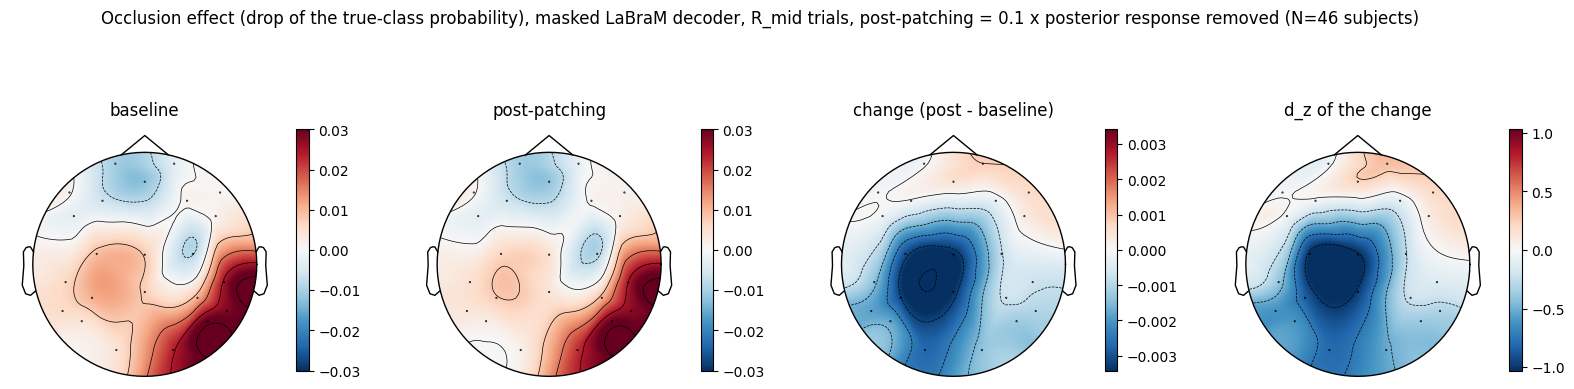

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP2 +0.0008, T2 +0.0006, FZ +0.0005
  min: CZ -0.0034, PZ -0.0034, P3 -0.0032


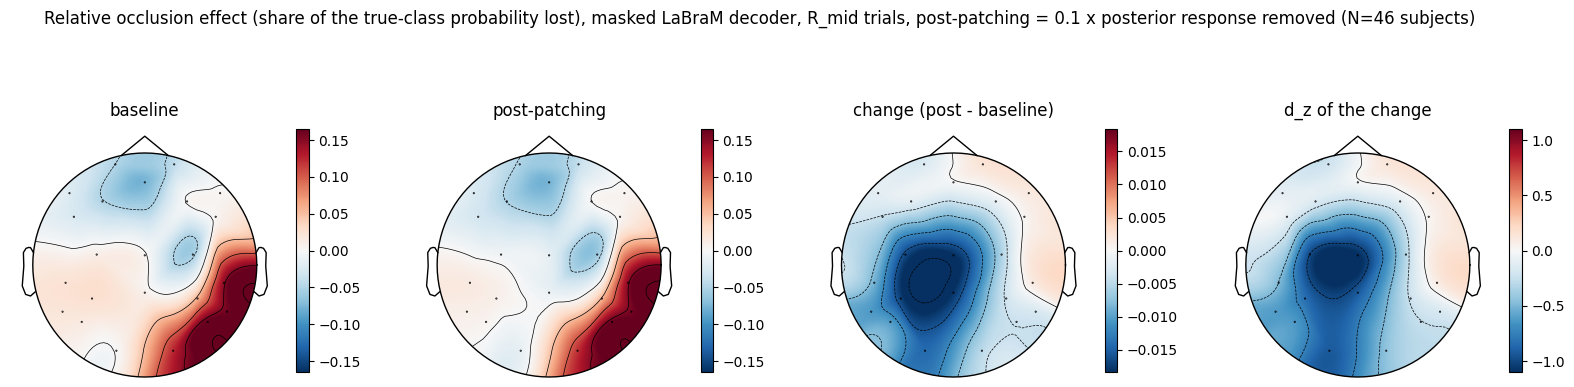

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: FP2 +0.0024, T2 +0.0017, T4 +0.0015
  min: CZ -0.0183, PZ -0.0180, P3 -0.0174
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
R_mid, attenuation 0.25: p_true 0.1733 -> 0.1631, change -0.0102 (t = -7.85, p = 5.629e-10, N = 46)


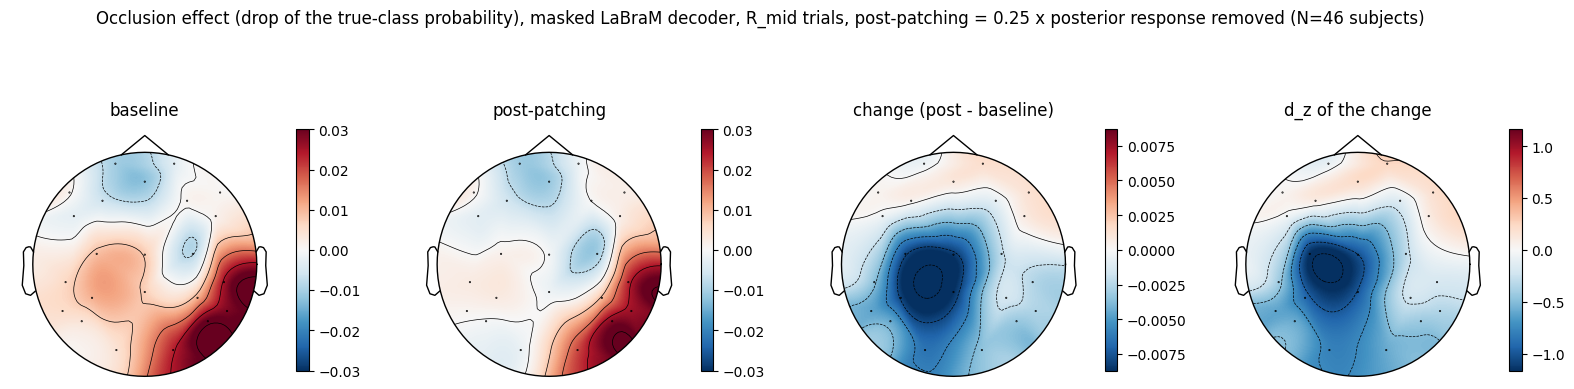

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP2 +0.0014, T2 +0.0013, FZ +0.0009
  min: PZ -0.0087, CZ -0.0083, P3 -0.0082


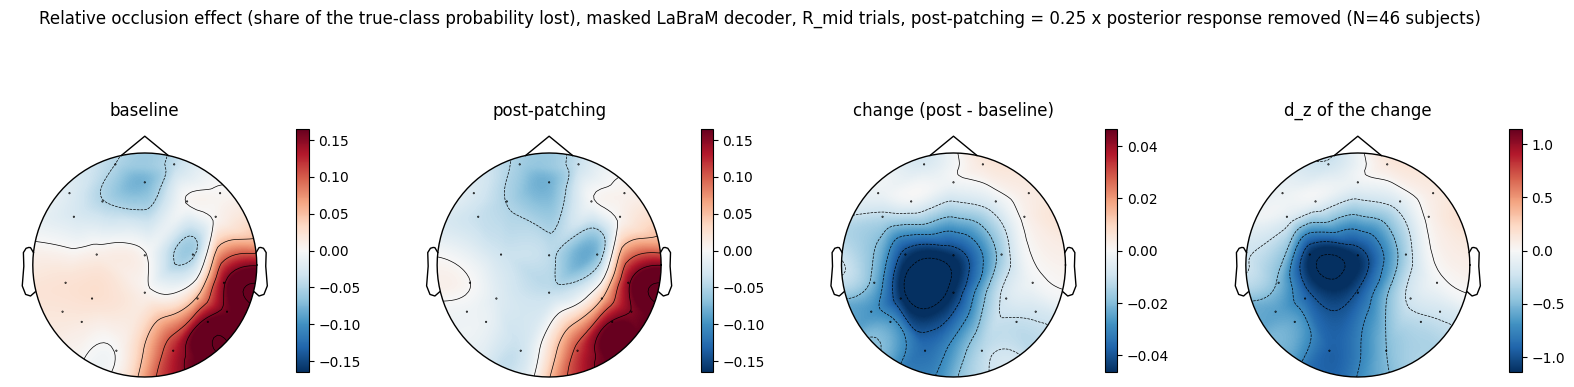

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: FP2 +0.0045, T2 +0.0035, F8 +0.0014
  min: PZ -0.0463, P3 -0.0458, CZ -0.0449
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
R_mid, attenuation 0.5: p_true 0.1733 -> 0.1538, change -0.0195 (t = -8.12, p = 2.325e-10, N = 46)


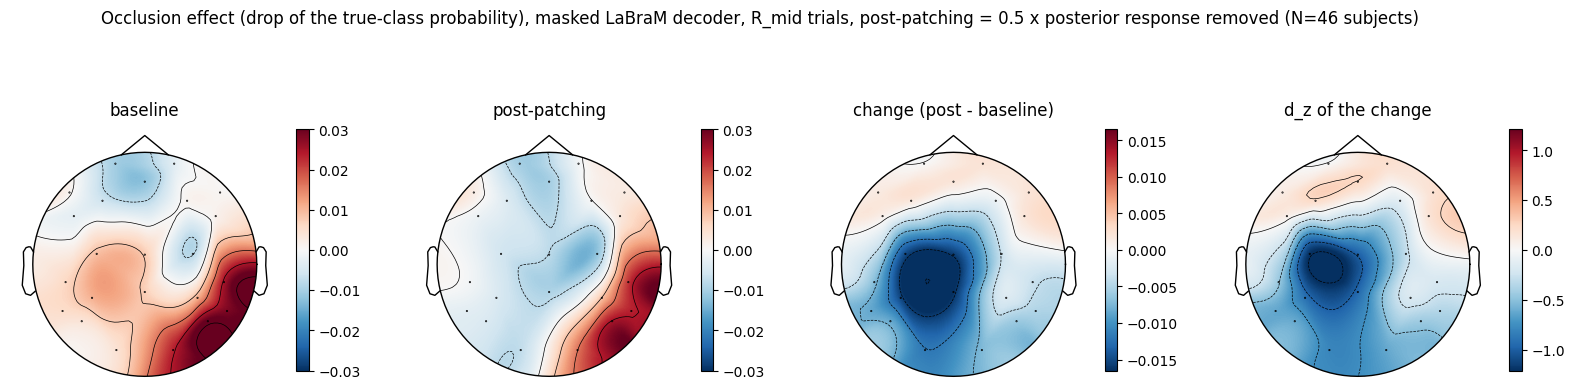

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP2 +0.0022, T2 +0.0021, FZ +0.0020
  min: PZ -0.0166, CZ -0.0156, P3 -0.0154


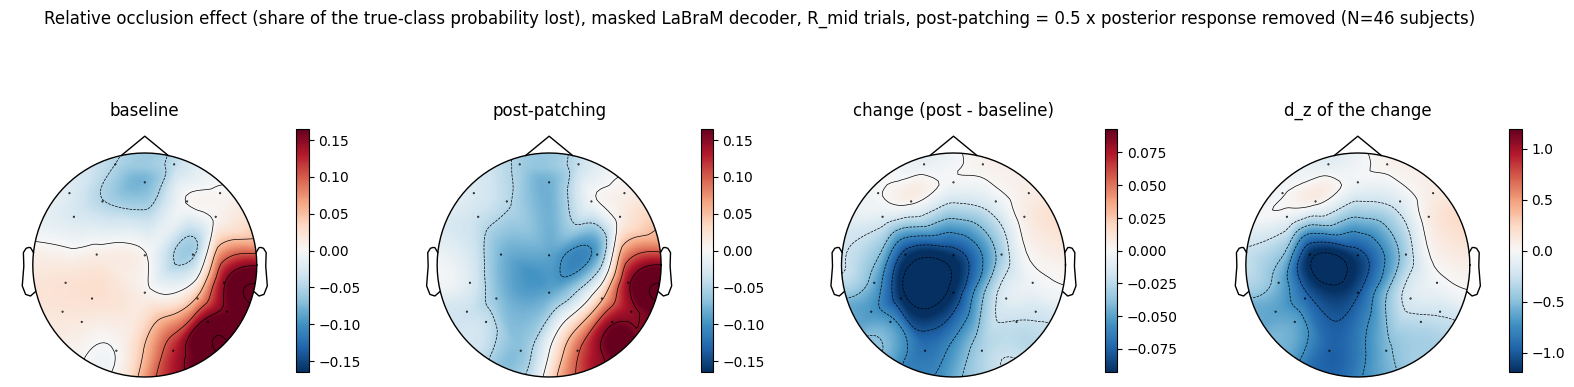

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: T2 +0.0060, F8 +0.0057, FP2 +0.0033
  min: PZ -0.0927, P3 -0.0923, CZ -0.0890


In [10]:
from scipy.stats import ttest_1samp

labram_injection_model = "class_10_22"  # masked class run trained on the baseline
labram_injection_condition = "right_2"  # --injection_conditions of the injection run
labram_attenuations = [0.1, 0.25, 0.5]  # --class_occlusion_injection values that were run

planted_class = settings.CONDITION_CLASS_IDS[labram_injection_condition]
planted_label = settings.LOCATION_CLASSES[labram_injection_condition]["label"]
regular_df = load_filtered_merged(labram_injection_model, mode="channel", sessions=("baseline",))
regular_df = regular_df[regular_df["label"] == planted_class]
for attenuation in labram_attenuations:
    injected_df = load_filtered_merged(f"{labram_injection_model}_inj_{attenuation:g}", mode="channel", sessions=("postpatch",))
    inj_df = pd.concat([regular_df, injected_df[injected_df["label"] == planted_class]], ignore_index=True)
    inj_df["p_true"] = inj_df["occlusion_effect"] + inj_df["occluded_p_true"]

    # the trial-level true-class probability (the same on every channel row of a trial): it should drop
    subject_p_true = inj_df.groupby(["session", "subject"])["p_true"].mean().unstack("session").dropna()
    drop = subject_p_true["postpatch"] - subject_p_true["baseline"]
    test = ttest_1samp(drop, 0)
    print(f"{planted_label}, attenuation {attenuation:g}: p_true {subject_p_true['baseline'].mean():.4f} -> "
          f"{subject_p_true['postpatch'].mean():.4f}, change {drop.mean():+.4f} (t = {test.statistic:.2f}, p = {test.pvalue:.4g}, N = {len(drop)})")

    model_label = f"masked LaBraM decoder, {planted_label} trials, post-patching = {attenuation:g} x posterior response removed"
    channel_change_topomaps(inj_df, "Occlusion effect (drop of the true-class probability)", model_label=model_label)
    channel_change_topomaps(inj_df, "Relative occlusion effect (share of the true-class probability lost)", relative=True,
                            model_label=model_label)


### LaBraM occlusion injection, within session
The check of the within-session comparison: two models trained on different trials, compared through their occlusion
maps. Every subject's baseline trials are split into two pseudo-sessions (`run_general_finetune.py --pseudo_session`):
one model trained on pseudo pre, one on pseudo post with the location-specific posterior response of the planted
condition removed (`plant_class_attenuation`), and one on pseudo post without a plant (null). Each model's occlusion is
run on its own test trials (`run_inference.py`). The maps compare the planted class's trials: pseudo pre model
("baseline") vs a pseudo post model ("post-patching").
- **Planted pair**: the occlusion effect drops at the posterior clusters.
- **Null pair**: no such pattern; its differences are those of two models trained on different trials, the floor the
  real within-session difference has to exceed.


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
planted pair, R_mid: p_true 0.1675 -> 0.1588, change -0.0087 (t = -0.50, p = 0.6218, N = 46)


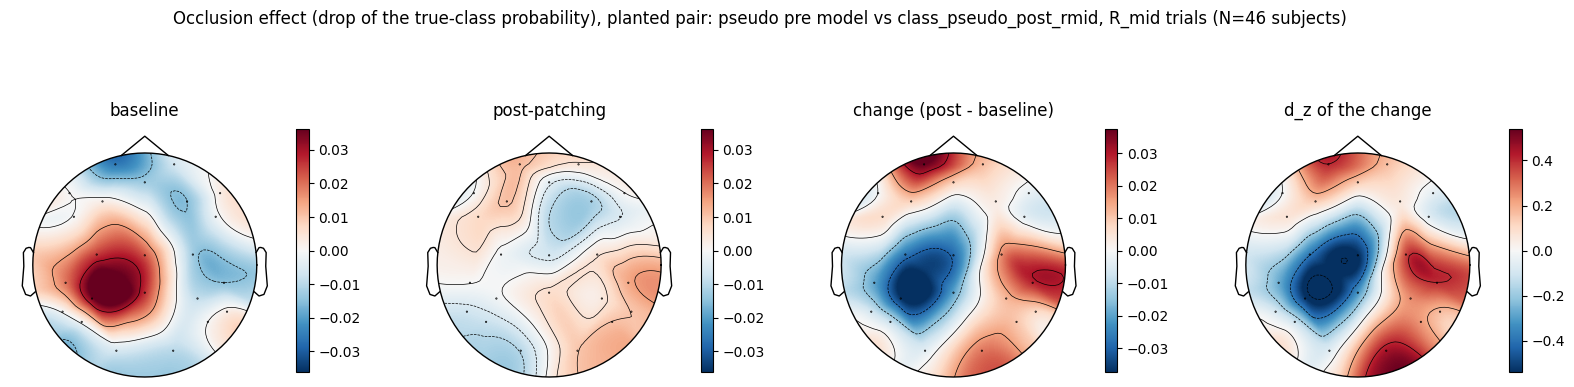

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: FP1 +0.0366, T4 +0.0285, O2 +0.0193
  min: P3 -0.0373, CZ -0.0286, C3 -0.0268


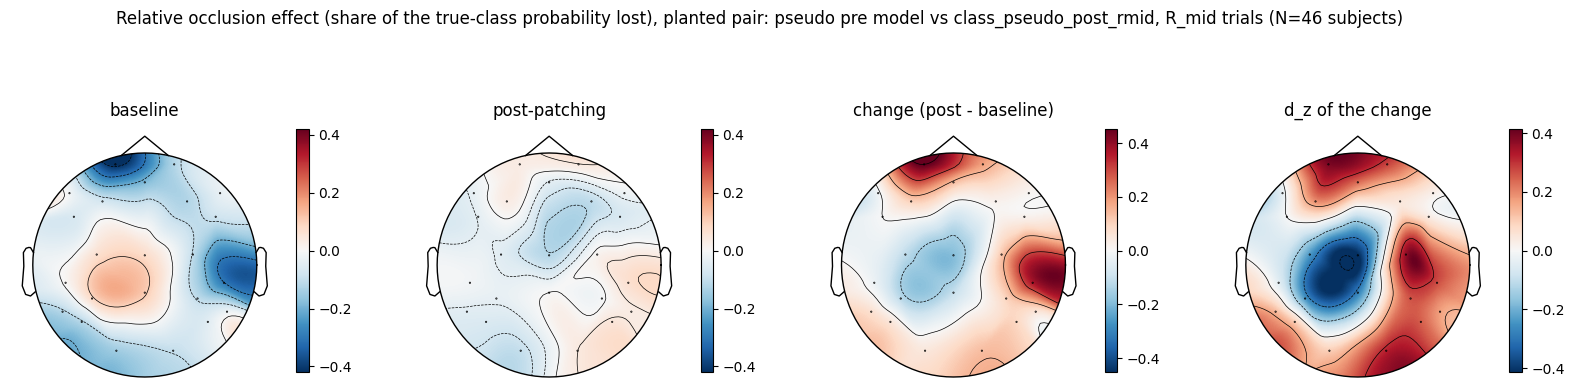

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: FP1 +0.4504, T4 +0.3650, FP2 +0.1811
  min: CZ -0.1916, P3 -0.1236, C3 -0.1164
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: all
Filtering for idxs: all
null pair, R_mid: p_true 0.1675 -> 0.1789, change +0.0114 (t = 0.62, p = 0.537, N = 46)


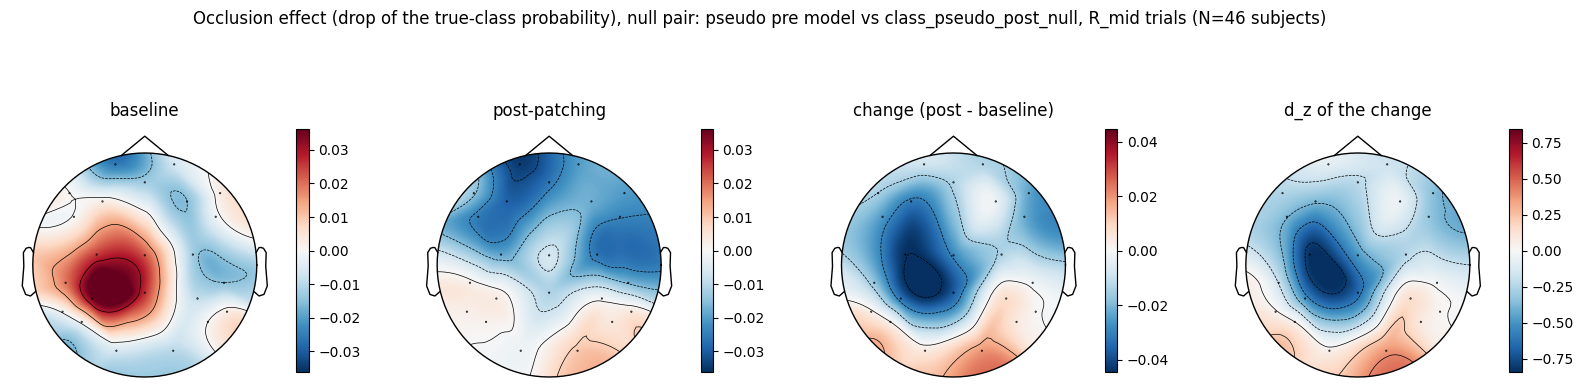

Occlusion effect (drop of the true-class probability), change (post - baseline):
  max: O2 +0.0188, P4 +0.0076, T6 +0.0048
  min: C3 -0.0445, PZ -0.0372, P3 -0.0334


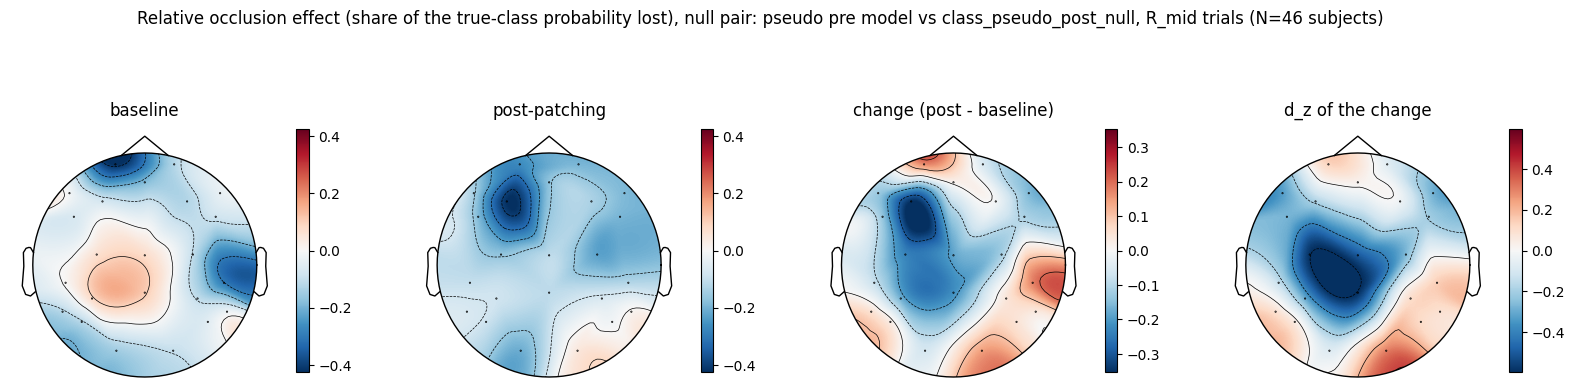

Relative occlusion effect (share of the true-class probability lost), change (post - baseline):
  max: T4 +0.1715, FP1 +0.1599, O2 +0.1390
  min: F3 -0.3521, C3 -0.2360, PZ -0.2165


In [11]:
pseudo_pre_model = "class_pseudo_pre"  # run_general_finetune.py --pseudo_session pre
pseudo_post_models = {"planted": "class_pseudo_post_rmid", "null": "class_pseudo_post_null"}  # --pseudo_session post (with / without plant)
pseudo_condition = "right_2"  # --plant_condition of the planted model

planted_class = settings.CONDITION_CLASS_IDS[pseudo_condition]
planted_label = settings.LOCATION_CLASSES[pseudo_condition]["label"]
pre_df = load_filtered_merged(pseudo_pre_model, mode="channel", sessions=("baseline",))
pre_df = pre_df[pre_df["label"] == planted_class]
for pair, post_model in pseudo_post_models.items():
    post_df = load_filtered_merged(post_model, mode="channel", sessions=("postpatch",))
    pair_df = pd.concat([pre_df, post_df[post_df["label"] == planted_class]], ignore_index=True)
    pair_df["p_true"] = pair_df["occlusion_effect"] + pair_df["occluded_p_true"]

    # the trial-level true-class probability per subject (different trials in the two halves, paired by subject)
    subject_p_true = pair_df.groupby(["session", "subject"])["p_true"].mean().unstack("session").dropna()
    change = subject_p_true["postpatch"] - subject_p_true["baseline"]
    test = ttest_1samp(change, 0)
    print(f"{pair} pair, {planted_label}: p_true {subject_p_true['baseline'].mean():.4f} -> {subject_p_true['postpatch'].mean():.4f}, "
          f"change {change.mean():+.4f} (t = {test.statistic:.2f}, p = {test.pvalue:.4g}, N = {len(change)})")

    model_label = f"{pair} pair: pseudo pre model vs {post_model}, {planted_label} trials"
    channel_change_topomaps(pair_df, "Occlusion effect (drop of the true-class probability)", model_label=model_label)
    channel_change_topomaps(pair_df, "Relative occlusion effect (share of the true-class probability lost)", relative=True,
                            model_label=model_label)
